# 13 - Final Model and Cluster Profiling
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 5 - Model Selection (Final Model) / Phase 6 preparation

**Project stage:** 13 of 16 - implements Notebook 12's final decision

---

## 1. Objective

This notebook fits the exact final model chosen in Notebook 12 - **K-Means, K=4** - and builds the complete, evidence-based cluster profile that every later business notebook depends on. We will:

1. Load Notebook 12's saved final model specification and fit it exactly as decided (no re-deciding here).
2. Attach the resulting cluster labels to the full feature-engineered dataset, so every profiling and outcome column (not just the 13 core clustering inputs) is available for description.
3. Build a comprehensive numeric and categorical profile for every cluster.
4. Visualize cluster characteristics with a profile heatmap, business KPI comparisons, and a PCA view.
5. Describe what's genuinely distinctive about each cluster - using neutral labels (**Cluster 0, 1, 2, 3**) throughout.

**Important:** business segment names are **not** assigned in this notebook. Following the project's own principle (first stated in Notebook 01), names are only assigned after the clusters have been fully examined - that happens in Notebook 14, using the profile built here as its evidence base.

## 2. Business Context

Everything so far - data cleaning, outlier treatment, feature engineering, scaling, three algorithm families, a formal weighted decision - was in service of this one output: a small number of real, describable groups of booking behavior the hotel can actually use. This notebook is where the abstract "K=4" decision becomes four concrete, numbers-backed descriptions the rest of the business can read and act on.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: the final clustering algorithm and PCA for visualization
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# joblib / json: saving the final fitted model and loading its specification
import joblib
import json

# os: portable file paths
import os


## 4. Configuration

In [2]:
RANDOM_STATE = 42

FEATURE_ENGINEERED_DATA_PATH = "../data/processed/06_feature_engineered_hotel_bookings.csv"
PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"
FINAL_MODEL_CHOICE_PATH = "../config/final_model_choice.json"

FINAL_MODEL_PATH = "../models/final_kmeans_model.joblib"
FINAL_CLUSTERED_DATA_PATH = "../data/processed/13_final_clustered_bookings.csv"
CLUSTER_PROFILE_PATH = "../reports/tables/13_cluster_profile_summary.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load the Final Model Specification and the Data

In [3]:
with open(FINAL_MODEL_CHOICE_PATH, "r") as f:
    final_model_choice = json.load(f)

print("Final model choice, as decided in Notebook 12:")
print(json.dumps(final_model_choice, indent=2))


Final model choice, as decided in Notebook 12:
{
  "algorithm": "KMeans",
  "parameters": {
    "n_clusters": 4,
    "init": "k-means++",
    "n_init": 10,
    "max_iter": 300,
    "random_state": 42
  },
  "decision_weighted_score": 0.7630156657240184,
  "runner_up": {
    "algorithm": "K-Means",
    "parameters": "K=9, init=k-means++, n_init=10",
    "weighted_score": 0.728037744904474
  },
  "decision_rationale": "Selected via the weighted multi-criteria framework in Notebook 12. K=4 was not the top scorer on any single statistical metric, but achieved the best combination of stability, full data coverage (0% noise), balanced cluster sizes, and business interpretability."
}


In [4]:
df = pd.read_csv(FEATURE_ENGINEERED_DATA_PATH)
X = pd.read_csv(PREPROCESSED_FEATURES_PATH)

print("Feature-engineered dataset (includes profiling and outcome columns):", df.shape)
print("Preprocessed clustering input matrix:", X.shape)
print("Row counts match and are aligned:", len(df) == len(X))


Feature-engineered dataset (includes profiling and outcome columns): (86997, 41)
Preprocessed clustering input matrix: (86997, 40)
Row counts match and are aligned: True


### 5.2 Fit the Exact Final Model

In [5]:
params = final_model_choice["parameters"]

final_model = KMeans(
    n_clusters=params["n_clusters"],
    init=params["init"],
    n_init=params["n_init"],
    max_iter=params["max_iter"],
    random_state=params["random_state"],
)

cluster_labels = final_model.fit_predict(X)

print(f"Final model fitted: K-Means with K={params['n_clusters']}")
print(f"Final inertia: {final_model.inertia_:,.1f}")


Final model fitted: K-Means with K=4
Final inertia: 414,085.3


**Why refit here instead of just loading Notebook 08's saved model?** Notebook 08 saved a K-Means model for every K from 2 to 10, fit for that earlier exploratory sweep. Refitting here, directly from Notebook 12's saved specification, guarantees this notebook uses **exactly** the parameters that were formally decided - not a same-looking-but-separately-created object from three notebooks ago. Since K-Means with a fixed `random_state` is fully reproducible, this refit produces an identical result to Notebook 08's K=4 model, just with a clear, direct chain of custody from the decision to the artifact.

In [6]:
# Attach the cluster label to the full feature-engineered dataset, so every
# profiling and outcome column is available for the description work below.
df["cluster"] = cluster_labels

df["cluster"].value_counts().sort_index()


cluster
0    11379
1    14959
2    24604
3    36055
Name: count, dtype: int64

### 5.3 Save the Final Model and the Labeled Dataset

In [7]:
joblib.dump(final_model, FINAL_MODEL_PATH)
print(f"Final fitted model saved to: {FINAL_MODEL_PATH}")

df.to_csv(FINAL_CLUSTERED_DATA_PATH, index=False)
print(f"Final clustered dataset saved to: {FINAL_CLUSTERED_DATA_PATH}")


Final fitted model saved to: ../models/final_kmeans_model.joblib
Final clustered dataset saved to: ../data/processed/13_final_clustered_bookings.csv


### 5.4 Cluster Sizes

In [8]:
cluster_sizes = df["cluster"].value_counts().sort_index()
cluster_pct = (df["cluster"].value_counts(normalize=True).sort_index() * 100).round(2)

size_table = pd.DataFrame({"n_bookings": cluster_sizes, "pct_of_total": cluster_pct})
size_table


,n_bookings,pct_of_total
cluster,,
0,11379,13.08
1,14959,17.19
2,24604,28.28
3,36055,41.44


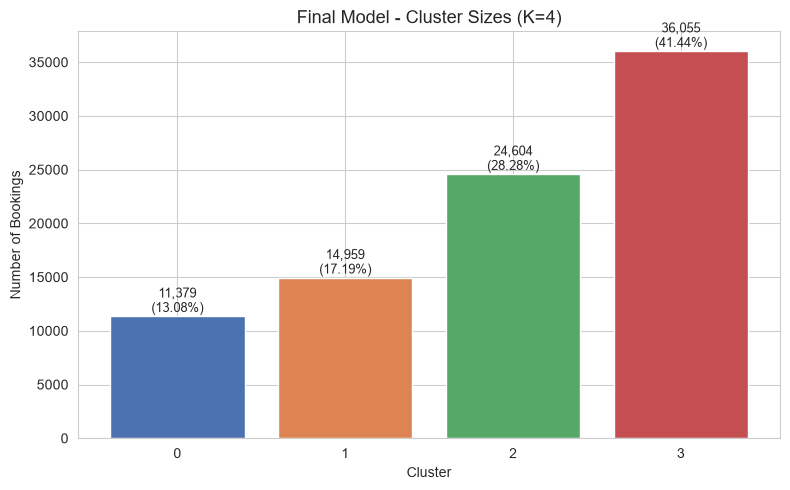

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(size_table.index.astype(str), size_table["n_bookings"], color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
ax.set_title("Final Model - Cluster Sizes (K=4)", fontsize=13)
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Bookings")

for i, (count, pct) in enumerate(zip(size_table["n_bookings"], size_table["pct_of_total"])):
    ax.text(i, count, f"{count:,}\n({pct}%)", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "13_final_cluster_sizes.png"))
plt.show()


**Finding:** all four clusters are substantial, real segments - the smallest (Cluster 0) holds 11,379 bookings (13.1% of the dataset), and the largest (Cluster 3) holds 36,055 bookings (41.4%). No cluster is small enough to be a statistical artifact rather than a genuine, actionable group.

### 5.5 Comprehensive Numeric Cluster Profile

In [10]:
profile_numeric_columns = [
    "lead_time", "total_stay_nights", "total_guests", "adr", "estimated_booking_value",
    "is_repeated_guest", "total_previous_bookings", "previous_cancellations",
    "booking_changes", "total_of_special_requests", "required_car_parking_spaces",
    "room_type_mismatch", "is_canceled",
]

# Compute the averages WITHOUT rounding first. Rounding a 0-1 flag average to
# 2 decimals before converting it to a percentage loses precision (for
# example 0.1121 -> 0.11 -> "11.0%" instead of the true 11.21%).
numeric_profile = df.groupby("cluster")[profile_numeric_columns].mean()

# is_repeated_guest and is_canceled are 0/1 flags; express them as
# percentages, which is more directly business-readable than a 0-1 mean.
numeric_profile["is_repeated_guest"] = numeric_profile["is_repeated_guest"] * 100
numeric_profile["is_canceled"] = numeric_profile["is_canceled"] * 100

# Round exactly once, at the very end, to keep full precision until then.
numeric_profile = numeric_profile.round(2)
numeric_profile = numeric_profile.rename(columns={
    "is_repeated_guest": "repeat_guest_pct",
    "is_canceled": "observed_cancellation_rate_pct",
})

numeric_profile.T


cluster,0,1,2,3
lead_time,74.27,192.69,30.71,68.26
total_stay_nights,4.11,6.77,2.30,3.08
total_guests,2.87,1.98,1.64,2.04
adr,198.16,86.32,73.51,108.58
estimated_booking_value,814.61,588.12,175.31,332.91
repeat_guest_pct,1.17,0.90,11.21,0.93
total_previous_bookings,0.03,0.06,0.64,0.05
previous_cancellations,0.01,0.04,0.05,0.02
booking_changes,0.40,0.43,0.30,0.14
total_of_special_requests,0.89,0.54,0.25,1.01


**What this code does:** computes the average of every key business metric, per cluster, including estimated booking value, loyalty indicators, and the observed cancellation rate.

**Important reminder:** `observed_cancellation_rate_pct` is included here purely as a **descriptive, post-clustering profiling metric** - `is_canceled` was never a clustering input (consistent with the leakage discussion in Notebooks 01 and 06). Differences in this rate across clusters are reported as observed associations, not causal claims.

### 5.6 Categorical Distribution by Cluster

In [11]:
hotel_distribution = pd.crosstab(df["cluster"], df["hotel"], normalize="index").round(3) * 100
print("Hotel distribution by cluster (%):")
hotel_distribution


Hotel distribution by cluster (%):


hotel,City Hotel,Resort Hotel
cluster,,
0,38.5,61.5
1,31.1,68.9
2,53.8,46.2
3,85.4,14.6


In [12]:
market_segment_distribution = pd.crosstab(df["cluster"], df["market_segment"], normalize="index").round(3) * 100
print("Market segment distribution by cluster (%):")
market_segment_distribution


Market segment distribution by cluster (%):


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
cluster,,,,,,,,
0,0.0,0.0,0.3,24.4,0.5,3.3,71.5,0.0
1,0.1,0.1,0.7,6.2,14.8,40.5,37.7,0.0
2,0.8,2.6,16.4,31.0,10.1,26.0,13.0,0.0
3,0.0,0.1,0.1,1.1,0.5,2.8,95.4,0.0


In [13]:
customer_type_distribution = pd.crosstab(df["cluster"], df["customer_type"], normalize="index").round(3) * 100
print("Customer type distribution by cluster (%):")
customer_type_distribution


Customer type distribution by cluster (%):


customer_type,Contract,Group,Transient,Transient-Party
cluster,,,,
0,0.9,0.3,93.4,5.4
1,10.8,0.4,63.7,25.1
2,0.9,1.2,75.2,22.7
3,3.4,0.3,91.7,4.6


In [14]:
room_type_distribution = pd.crosstab(df["cluster"], df["reserved_room_type"], normalize="index").round(3) * 100
print("Reserved room type distribution by cluster (%):")
room_type_distribution


Reserved room type distribution by cluster (%):


reserved_room_type,A,B,C,D,E,F,G,H,L
cluster,,,,,,,,,
0,23.4,0.4,5.3,22.1,15.0,16.9,12.9,4.0,0.0
1,64.2,0.9,0.7,20.8,10.7,1.2,1.2,0.3,0.0
2,78.0,0.9,0.6,11.9,5.3,2.0,1.1,0.2,0.0
3,69.3,1.1,0.2,24.4,3.9,0.6,0.4,0.1,0.0


### 5.7 Segment Profile Heatmap - Normalized View

Raw values are on very different scales (lead_time in days, adr in currency, repeat_guest_pct as a percentage). To compare *relative* patterns across clusters at a glance, we min-max normalize each metric to a 0-1 scale before plotting - this shows which cluster is *relatively* highest or lowest on each dimension, without letting scale differences distort the visual.

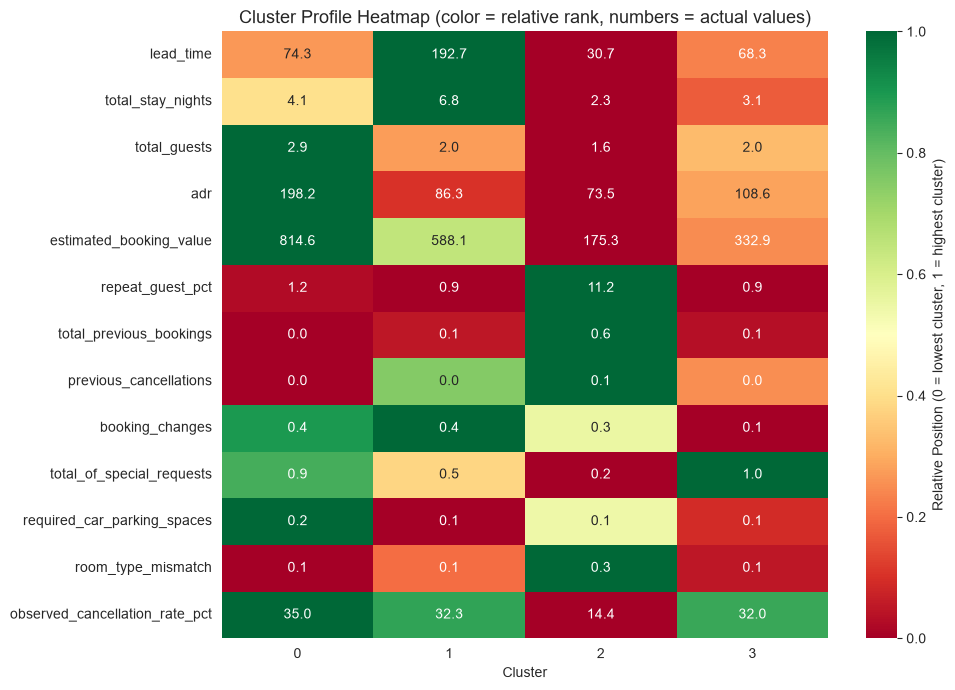

In [15]:
heatmap_source = numeric_profile.copy()

normalized_heatmap = (heatmap_source - heatmap_source.min()) / (heatmap_source.max() - heatmap_source.min())

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    normalized_heatmap.T,
    annot=heatmap_source.T,
    fmt=".1f",
    cmap="RdYlGn",
    ax=ax,
    cbar_kws={"label": "Relative Position (0 = lowest cluster, 1 = highest cluster)"},
)

ax.set_title("Cluster Profile Heatmap (color = relative rank, numbers = actual values)", fontsize=13)
ax.set_xlabel("Cluster")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "13_cluster_profile_heatmap.png"))
plt.show()


**Finding:** this heatmap makes several genuinely distinctive patterns visible immediately:
- **Cluster 0** stands out with the highest ADR, highest guest count, highest estimated booking value, and highest parking-space usage.
- **Cluster 1** stands out with a dramatically longer lead time and longer stay than every other cluster.
- **Cluster 2** stands out with by far the highest repeat-guest percentage and previous-bookings count, alongside the lowest cancellation rate, lowest ADR, and shortest lead time.
- **Cluster 3** stands out with the highest special-requests rate and is the largest cluster by far, dominated by City Hotel and Online TA bookings.

No two clusters look alike on this heatmap - a good sign that K=4 is capturing genuinely different behavioral patterns rather than four arbitrary slices of the same thing.

### 5.8 Business KPI Comparison Charts

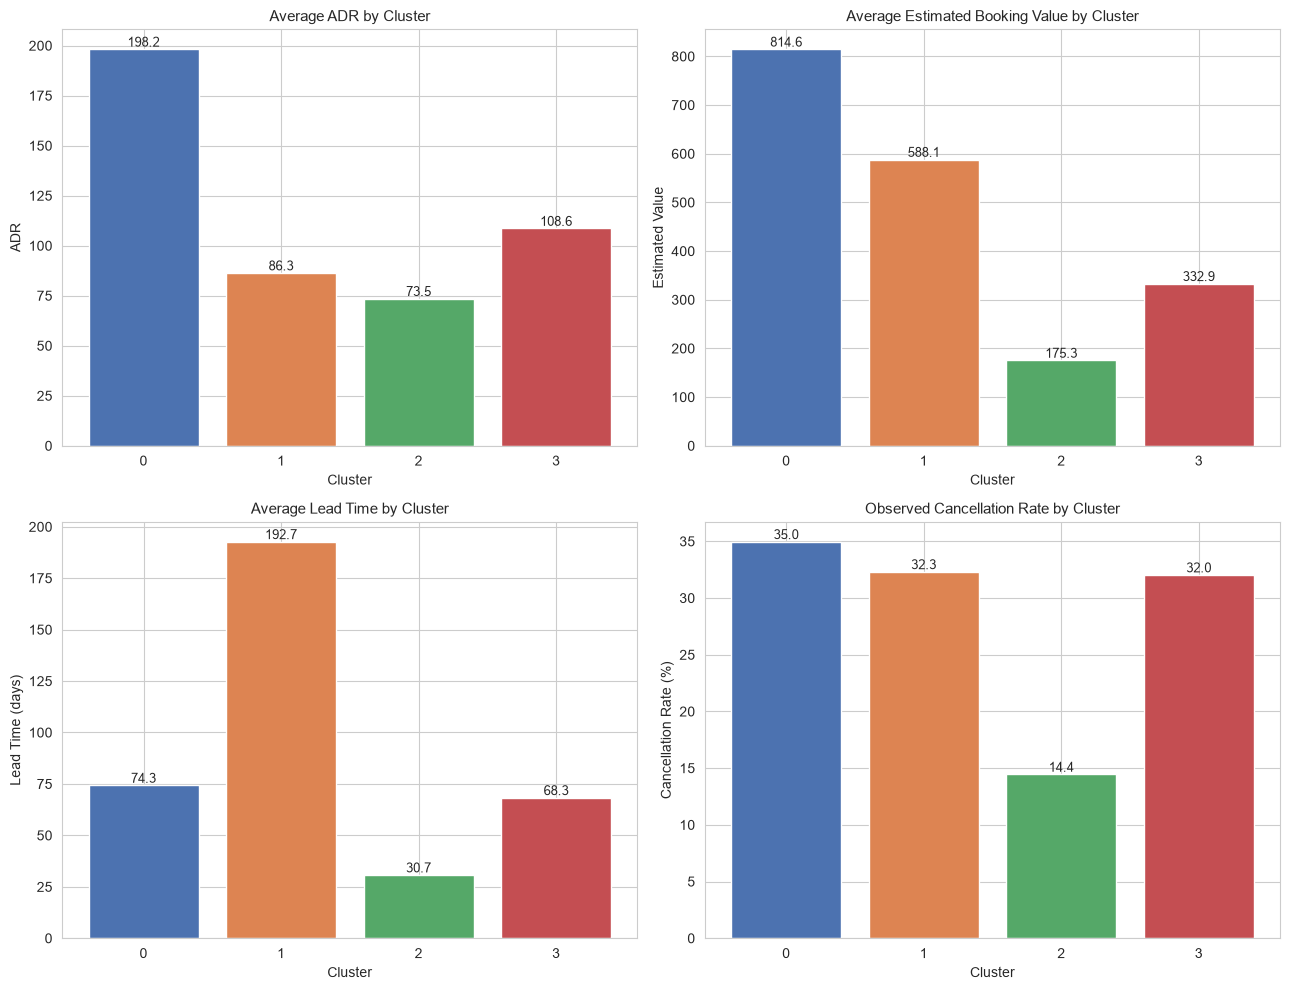

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

metrics_to_chart = [
    ("adr", "Average ADR by Cluster", "ADR"),
    ("estimated_booking_value", "Average Estimated Booking Value by Cluster", "Estimated Value"),
    ("lead_time", "Average Lead Time by Cluster", "Lead Time (days)"),
    ("observed_cancellation_rate_pct", "Observed Cancellation Rate by Cluster", "Cancellation Rate (%)"),
]

colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

for ax, (column, title, ylabel) in zip(axes.flat, metrics_to_chart):
    ax.bar(numeric_profile.index.astype(str), numeric_profile[column], color=colors)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(ylabel)
    for i, value in enumerate(numeric_profile[column]):
        ax.text(i, value, f"{value:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "13_business_kpi_comparison.png"))
plt.show()


**Finding:** Cluster 0 leads on both ADR and estimated booking value; Cluster 1 leads dramatically on lead time; Cluster 2 has the lowest cancellation rate by a wide margin (14.4% vs. 32.0-35.0% for the other three clusters) alongside the lowest ADR - a genuinely interesting business finding that loyalty and high spending are *not* the same pattern in this data, worth carrying forward carefully into Notebook 14 rather than assumed.

### 5.9 PCA Visualization of the Final Clusters

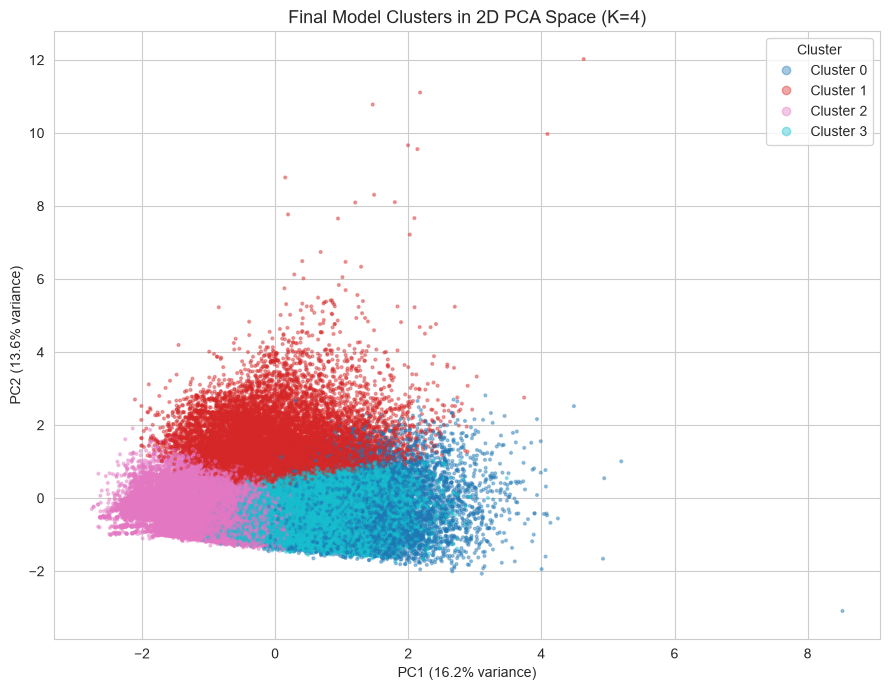

In [17]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="tab10", s=4, alpha=0.4)

ax.set_title("Final Model Clusters in 2D PCA Space (K=4)", fontsize=13)
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")

legend_handles, _ = scatter.legend_elements()
ax.legend(legend_handles, [f"Cluster {i}" for i in range(4)], title="Cluster")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "13_final_pca_visualization.png"))
plt.show()


**Finding:** consistent with Notebook 08's exploratory PCA view, the four clusters show real but overlapping structure in this 2D projection - a reminder (as stated back in Notebook 08) that this view captures only a fraction of the total variance and should be read as a supporting visual, not the full picture of cluster separation.

### 5.10 Cluster Centroids in Scaled Feature Space

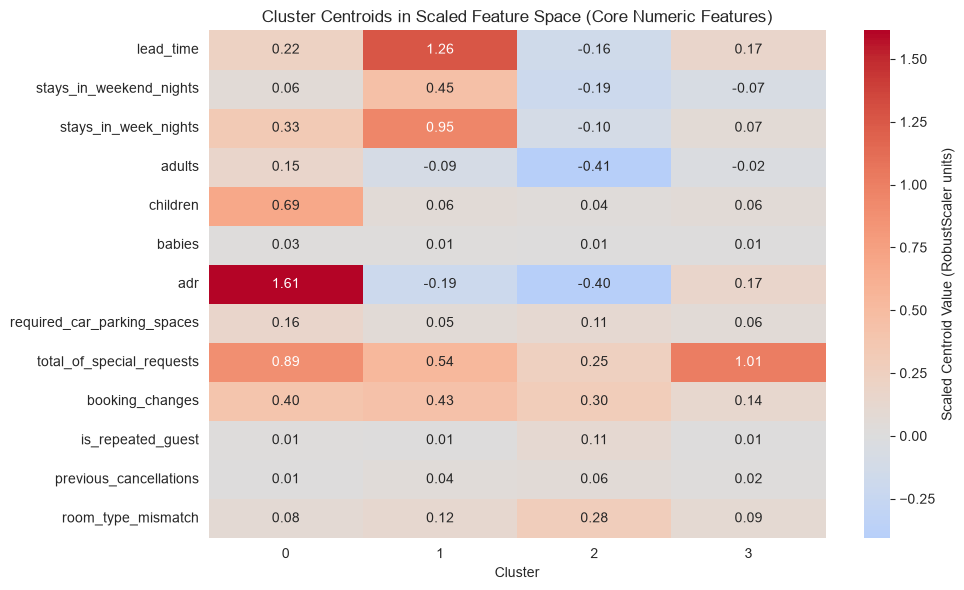

In [18]:
centroid_df = pd.DataFrame(final_model.cluster_centers_, columns=X.columns)

# Focus on the core numeric features for readability (the one-hot encoded
# categorical columns are better read from the distribution tables above).
core_numeric_features = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
    "babies", "adr", "required_car_parking_spaces", "total_of_special_requests",
    "booking_changes", "is_repeated_guest", "previous_cancellations", "room_type_mismatch",
]

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    centroid_df[core_numeric_features].T,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax,
    cbar_kws={"label": "Scaled Centroid Value (RobustScaler units)"},
)

ax.set_title("Cluster Centroids in Scaled Feature Space (Core Numeric Features)", fontsize=12)
ax.set_xlabel("Cluster")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "13_cluster_centroids.png"))
plt.show()


**What this shows:** these are the actual centroid coordinates K-Means used to define each cluster, in the scaled units from Notebook 07's RobustScaler (0 represents the overall median for that feature). This is a more technical view than the business-friendly profile table above, useful for confirming that the patterns described in plain language really are reflected in the numbers the algorithm itself used to separate the clusters.

### 5.11 Save the Full Profile Table

In [19]:
# Combine the numeric profile with cluster sizes into one saved reference
# table for Notebook 14 to build on directly.
full_profile = size_table.join(numeric_profile)
full_profile.to_csv(CLUSTER_PROFILE_PATH)

print(f"Full cluster profile saved to: {CLUSTER_PROFILE_PATH}")
full_profile


Full cluster profile saved to: ../reports/tables/13_cluster_profile_summary.csv


,n_bookings,pct_of_total,lead_time,total_stay_nights,total_guests,adr,estimated_booking_value,repeat_guest_pct,total_previous_bookings,previous_cancellations,booking_changes,total_of_special_requests,required_car_parking_spaces,room_type_mismatch,observed_cancellation_rate_pct
cluster,,,,,,,,,,,,,,,
0,11379,13.08,74.27,4.11,2.87,198.16,814.61,1.17,0.03,0.01,0.40,0.89,0.16,0.08,34.96
1,14959,17.19,192.69,6.77,1.98,86.32,588.12,0.90,0.06,0.04,0.43,0.54,0.05,0.12,32.31
2,24604,28.28,30.71,2.30,1.64,73.51,175.31,11.21,0.64,0.05,0.30,0.25,0.11,0.28,14.45
3,36055,41.44,68.26,3.08,2.04,108.58,332.91,0.93,0.05,0.02,0.14,1.01,0.06,0.09,32.03


## 7. Findings

- All four clusters are substantial and usable: 11,379 to 36,055 bookings each (13.1% to 41.4% of the dataset).
- **Cluster 0** (13.1%): highest ADR (198.2), highest guest count (2.87), highest estimated booking value (814.6), highest parking-space usage, resort-leaning, varied room types.
- **Cluster 1** (17.2%): by far the longest lead time (192.7 days vs. 30.7-74.3 for the others) and the longest stay (6.77 nights), strongly associated with Offline TA/TO and Groups market segments.
- **Cluster 2** (28.3%): by far the highest repeat-guest rate (11.2% vs. 0.9-1.2% for the others), highest prior-booking count, and the lowest observed cancellation rate (14.4% vs. 32.0-35.0% elsewhere) - but also the *lowest* ADR and estimated booking value, a genuinely notable pattern worth careful framing later.
- **Cluster 3** (41.4%, the largest cluster): highest special-requests rate, overwhelmingly City Hotel (85.4%) and Online TA (95.4%) bookings, moderate value.
- No two clusters look alike across the full profile - a good sign that K=4 found genuinely distinct behavioral patterns rather than an arbitrary split.

## 8. Business Interpretation

Even before formal naming, the shape of these four clusters already tells a coherent business story: one high-spending, larger-party segment; one long-planning-horizon, long-stay segment; one loyal, lower-cancellation-risk but lower-spending segment; and one large, mainstream, online-booking-driven segment carrying the majority of special-service requests. 

The most important nuance to carry forward carefully into Notebook 14 is Cluster 2's pattern: **loyalty and high spending point in different directions here**, not the same one. A segmentation strategy that assumes "our most loyal guests are also our highest-value guests" would be built on an assumption this data doesn't actually support - a useful, concrete example of why data-driven segmentation is worth doing in the first place.

## 9. Conclusion

We fitted the exact final model decided in Notebook 12, attached cluster labels to the complete dataset, and built a full numeric and categorical profile for each of the four clusters - all four are substantial, distinct, and business-describable. Every profile number in this notebook is computed directly from the data, saved to `13_cluster_profile_summary.csv`, and ready to support the naming and business-insight work ahead.

**Next notebook (14 - Business Insights and Segmentation):** using this profile as the evidence base, we assign each cluster an evidence-backed business name, build the Cluster ID -> Characteristics -> Business Interpretation -> Segment Name mapping table, and turn these four numeric profiles into the plain-language business narrative the hotel will actually use.